# Bias and Breakpoint 

Based on https://www.kaggle.com/datasets/cdaclab/unisolar

In [43]:
import pandas as pd
from matplotlib import pyplot as plt
from scipy.signal import welch
import numpy as np

In [ ]:
# Specify the path to the dataset
DATA_PATH = "Solar_Energy_Generation.csv"

In [ ]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

df

,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,NaN
1,2,1,2020-01-01 00:30:00,NaN
2,2,1,2020-01-01 00:45:00,NaN
3,2,1,2020-01-01 01:00:00,NaN
4,2,1,2020-01-01 01:15:00,NaN
...,...,...,...,...
2731941,5,42,2022-04-23 22:45:00,NaN
2731942,5,42,2022-04-23 23:00:00,NaN
2731943,5,42,2022-04-23 23:15:00,NaN
2731944,5,42,2022-04-23 23:30:00,NaN


In [7]:
# Select one site with CampusKey 1 and SiteKey 1

df_site = df[(df['CampusKey'] == 2) & (df['SiteKey'] == 1)]

df_site



,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,NaN
1,2,1,2020-01-01 00:30:00,NaN
2,2,1,2020-01-01 00:45:00,NaN
3,2,1,2020-01-01 01:00:00,NaN
4,2,1,2020-01-01 01:15:00,NaN
...,...,...,...,...
79314,2,1,2022-04-23 22:45:00,NaN
79315,2,1,2022-04-23 23:00:00,NaN
79316,2,1,2022-04-23 23:15:00,NaN
79317,2,1,2022-04-23 23:30:00,NaN


In [8]:
# Replace NaN values in SolarGeneration with 0, as we assume that it is due to night time.

df_site['SolarGeneration'] = df_site['SolarGeneration'].fillna(0)
df_site

C:\Users\JanderM\AppData\Local\Temp\ipykernel_18324\3073260574.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_site['SolarGeneration'] = df_site['SolarGeneration'].fillna(0)


,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,0.0
1,2,1,2020-01-01 00:30:00,0.0
2,2,1,2020-01-01 00:45:00,0.0
3,2,1,2020-01-01 01:00:00,0.0
4,2,1,2020-01-01 01:15:00,0.0
...,...,...,...,...
79314,2,1,2022-04-23 22:45:00,0.0
79315,2,1,2022-04-23 23:00:00,0.0
79316,2,1,2022-04-23 23:15:00,0.0
79317,2,1,2022-04-23 23:30:00,0.0


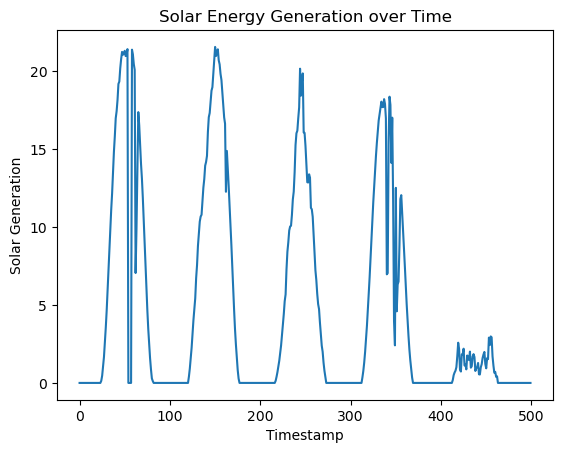

In [24]:
# Plot df site with SolarGeneration
plt.plot(df_site['SolarGeneration'].head(500))
plt.xlabel('Timestamp')
plt.ylabel('Solar Generation')
plt.title('Solar Energy Generation over Time')
plt.show()

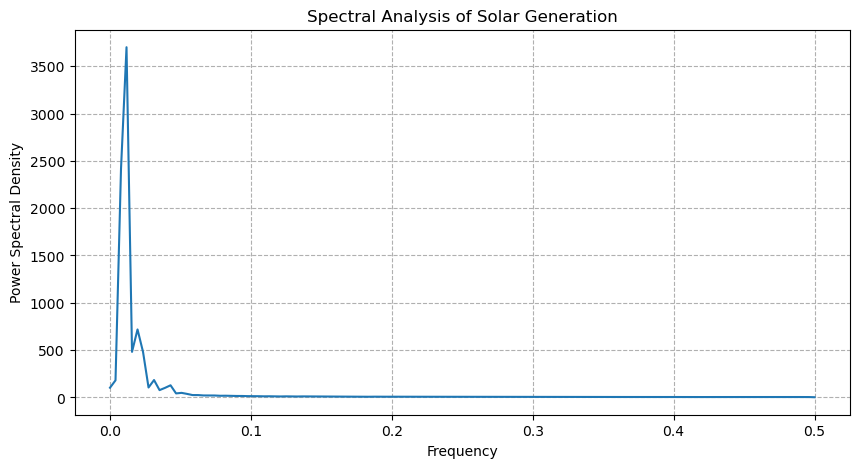

0.01171875


In [36]:
# Create Spectral Analysis of df_site['SolarGeneration'] using FFT

solar_data = df_site['SolarGeneration']

frequencies, psd = welch(solar_data)

# Plot erstellen
plt.figure(figsize=(10, 5))
plt.plot(
    frequencies, psd
)  
plt.xlabel('Frequency')
plt.ylabel('Power Spectral Density')
plt.title('Spectral Analysis of Solar Generation')
plt.grid(True, which='both', linestyle='--')
plt.show()

# return the max frequency

max_freq = frequencies[psd.argmax()]
print(max_freq)

In [32]:
# Theoretical frequency of solar generation is 1 cycle per day, which is 1/96 cycles per 15-minute interval (since there are 96 intervals in a day).

1/96

0.010416666666666666

In [51]:
# create numpy array where row is sample and column is time step, with n*96 time steps per row

pattern_reps = 10
sample_size = 96 * pattern_reps
n_samples = 100

n_values = n_samples * sample_size

# transform solar_data to numpy array with rows of 96*pattern_reps time steps
solar_data = np.array(solar_data)[ : n_values].reshape(-1, sample_size)

solar_data.shape


(40, 960)

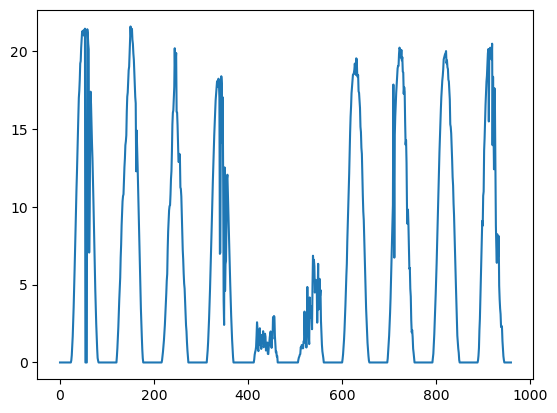

In [53]:
# plot first row of solar_data

plt.plot(solar_data[0]);


In [ ]:
# Random sample from generator

path = "../../artifacts/generation/0a596870dd252c71/trajectory.npz"

data = np.load(path)["x"]

data.shape

(768,)

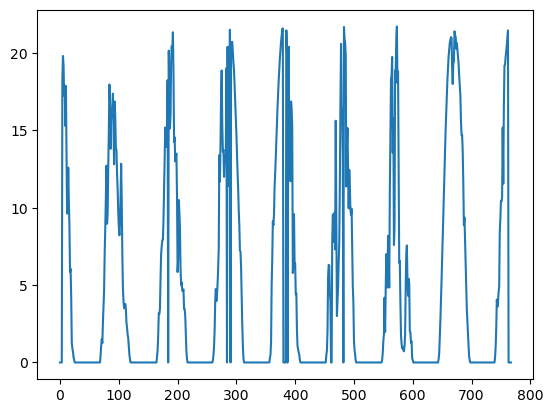

In [60]:
# plot data

plt.plot(data);

The generator seems to create correct samples.

# Entanglement

Does the Unisolar dataset provide a natural experiment where the wavelength of the time series stays constant throught the year, while the amplitude changes with summer and winter? If so, we can use this as in vivo experiment to see whether TSFMs shorten the wavelength for winter samples compared to summer samples, exhibiting entanglement as failure mode. We can test if these findings reproduce from in vitro to in vivo experiments.

In [47]:
# split df_site into summer and winter semester based on the timestamp

df_site['Timestamp'] = pd.to_datetime(df_site['Timestamp'])

# data is from Australia, so summer is from October to March and winter is from April to September

df_winter = df_site[(df_site['Timestamp'].dt.month >= 4) & (df_site['Timestamp'].dt.month <= 9)]
df_summer = df_site[(df_site['Timestamp'].dt.month >= 10) | (df_site['Timestamp'].dt.month <= 3)]

df_winter.shape, df_summer.shape


C:\Users\JanderM\AppData\Local\Temp\ipykernel_18324\543275802.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_site['Timestamp'] = pd.to_datetime(df_site['Timestamp'])


((36545, 4), (42774, 4))

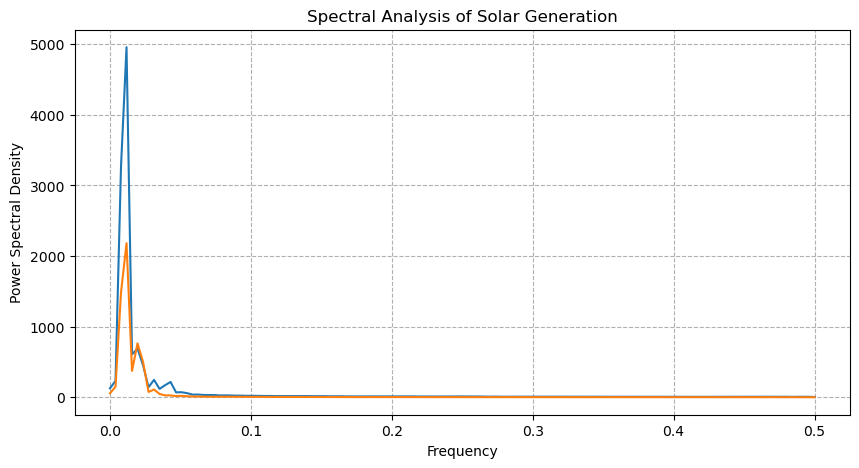

Summer Max Frequency: 0.01171875
Winter Max Frequency: 0.01171875


In [40]:
# compare the spectral analysis of summer and winter semesters

summersolar_data = df_summer['SolarGeneration']
wintersolar_data = df_winter['SolarGeneration']

summerfrequencies, summerspd = welch(summersolar_data)
winterfrequencies, winterspd = welch(wintersolar_data)

# Plot erstellen
plt.figure(figsize=(10, 5))
plt.plot(
    summerfrequencies, summerspd
)  
plt.plot(
    winterfrequencies, winterspd
)
plt.xlabel('Frequency')
plt.ylabel('Power Spectral Density')
plt.title('Spectral Analysis of Solar Generation')
plt.grid(True, which='both', linestyle='--')
plt.show()

# return the max frequency

summer_max_freq = summerfrequencies[summerspd.argmax()]
winter_max_freq = winterfrequencies[winterspd.argmax()]
print("Summer Max Frequency:", summer_max_freq)
print("Winter Max Frequency:", winter_max_freq)


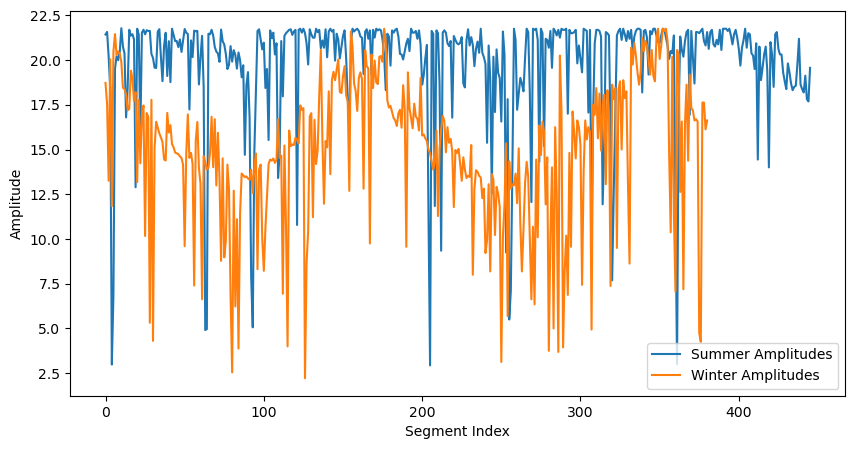

Average Summer Amplitude: 19.84528699551561 3.1717747748796024
Average Winter Amplitude: 14.958485564305123 4.046253276454141


In [46]:
# Calculate amplitude of solar generation for summer and winter semesters for each 96 time step segment

summer_amplitudes = []
winter_amplitudes = []

for i in range(0, len(summersolar_data), 96):
    segment = summersolar_data.iloc[i:i+96]
    amplitude = segment.max() - segment.min()
    summer_amplitudes.append(amplitude)

for i in range(0, len(wintersolar_data), 96):
    segment = wintersolar_data.iloc[i:i+96]
    amplitude = segment.max() - segment.min()
    winter_amplitudes.append(amplitude)

# plot the amplitudes of summer and winter semesters

plt.figure(figsize=(10, 5))
plt.plot(summer_amplitudes, label='Summer Amplitudes')
plt.plot(winter_amplitudes, label='Winter Amplitudes')
plt.xlabel('Segment Index')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

print("Average Summer Amplitude:", np.mean(summer_amplitudes), np.std(summer_amplitudes))
print("Average Winter Amplitude:", np.mean(winter_amplitudes), np.std(winter_amplitudes))